In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

from tensorflow.keras import layers, models

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)
print("MobileNetV2 environment ready!")

TensorFlow version: 2.21.0
MobileNetV2 environment ready!


In [2]:
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(exist_ok=True)

train_df = pd.read_csv(DATASET_DIR / "train_split.csv")
val_df = pd.read_csv(DATASET_DIR / "val_split.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 2929
Validation images: 733


In [3]:
IMG_SIZE = 224
BATCH_SIZE = 8


def load_mobilenet_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    # MobileNetV2 preprocessing: pixels become -1 to 1
    image = preprocess_input(image)

    label = tf.cast(label, tf.int32)

    return image, label

In [4]:
def create_mobilenet_dataset(dataframe, training=False):

    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42
        )

    dataset = dataset.map(
        load_mobilenet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_mobilenet_dataset(
    train_df,
    training=True
)

val_ds = create_mobilenet_dataset(
    val_df,
    training=False
)

print("MobileNetV2 datasets created successfully!")

MobileNetV2 datasets created successfully!


In [5]:
for images, labels in train_ds.take(1):

    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image shape: (8, 224, 224, 3)
Label shape: (8,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0000007


In [6]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 pretrained model loaded!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
MobileNetV2 pretrained model loaded!


In [7]:
inputs = layers.Input(shape=(224, 224, 3))

# Extract image features
x = base_model(inputs, training=False)

# Convert feature maps into a vector
x = layers.GlobalAveragePooling2D()(x)

# Prevent overfitting
x = layers.Dropout(0.3)(x)

# Five DR categories
outputs = layers.Dense(
    5,
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs
)

print("MobileNetV2 classifier created successfully!")

MobileNetV2 classifier created successfully!


In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
classes = np.unique(train_df["diagnosis"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)


Class weights:
{0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


In [10]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.000001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

In [11]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=5,

    class_weight=class_weights,

    callbacks=callbacks,

    shuffle=False
)

Epoch 1/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 71s 183ms/step - accuracy: 0.5674 - loss: 1.3545 - val_accuracy: 0.6535 - val_loss: 0.8291 - learning_rate: 0.0010
Epoch 2/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 67s 181ms/step - accuracy: 0.6818 - loss: 1.0385 - val_accuracy: 0.7040 - val_loss: 0.7641 - learning_rate: 0.0010
Epoch 3/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 66s 180ms/step - accuracy: 0.6996 - loss: 0.9877 - val_accuracy: 0.6794 - val_loss: 0.7736 - learning_rate: 0.0010
Epoch 4/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 67s 182ms/step - accuracy: 0.7364 - loss: 0.8498 - val_accuracy: 0.7422 - val_loss: 0.6747 - learning_rate: 5.0000e-04
Epoch 5/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 67s 183ms/step - accuracy: 0.7549 - loss: 0.8142 - val_accuracy: 0.7258 - val_loss: 0.6938 - learning_rate: 5.0000e-04


In [12]:
mobilenet_best_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_best.keras"
)

print("Best MobileNetV2 model loaded successfully!")

Best MobileNetV2 model loaded successfully!


In [13]:
# Actual validation labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

# Prediction probabilities
y_prob = mobilenet_best_model.predict(val_ds)

# Convert probabilities to predicted classes
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

print("Predictions generated successfully!")

92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 148ms/step
Actual labels: (733,)
Predicted labels: (733,)
Predictions generated successfully!


In [14]:
from sklearn.metrics import classification_report

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

           No DR       0.94      0.94      0.94       361
            Mild       0.44      0.51      0.47        74
        Moderate       0.73      0.59      0.66       200
          Severe       0.30      0.51      0.38        39
Proliferative DR       0.47      0.44      0.46        59

        accuracy                           0.74       733
       macro avg       0.58      0.60      0.58       733
    weighted avg       0.76      0.74      0.75       733



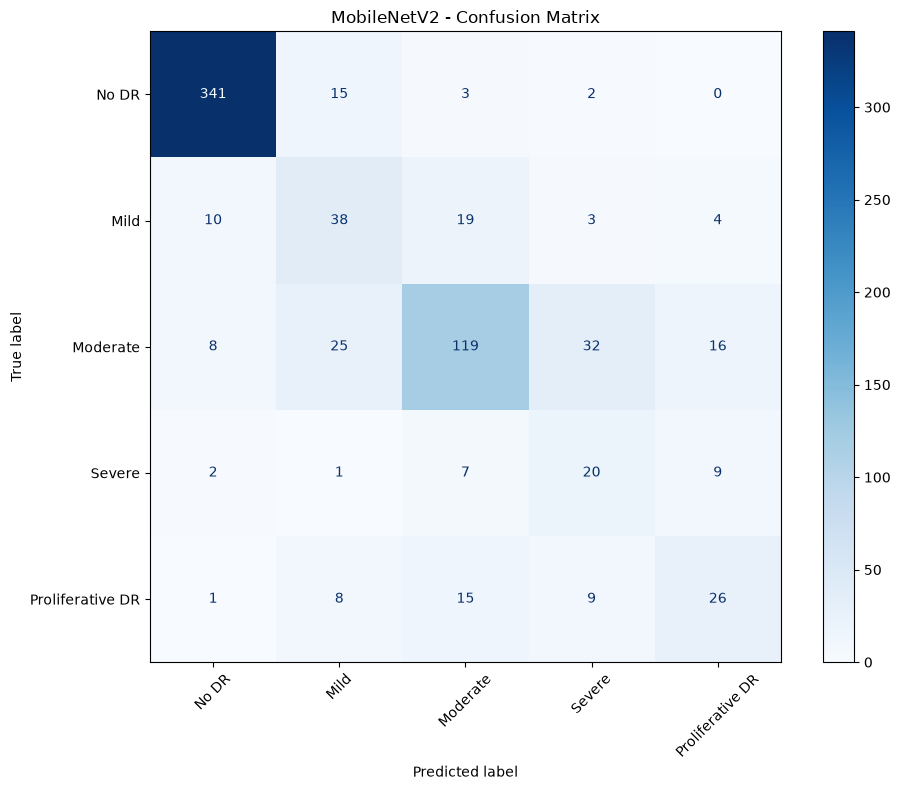

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Load the best model from the first training stage

model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_best.keras"
)

# Retrieve the MobileNetV2 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
)

print("Best model loaded successfully!")
print("MobileNetV2 layers:", len(base_model.layers))

Best model loaded successfully!
MobileNetV2 layers: 154


In [17]:
# Allow fine-tuning
base_model.trainable = True

# Keep the first layers frozen
fine_tune_at = len(base_model.layers) - 20

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Train the last layers, but keep BatchNormalization frozen
for layer in base_model.layers[fine_tune_at:]:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

    else:
        layer.trainable = True

print("Fine-tuning configuration completed!")

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Fine-tuning configuration completed!
Trainable layers: 13


In [18]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")

Fine-tuning model compiled successfully!


In [19]:
finetune_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.000001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_finetuned_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

In [20]:
fine_tune_history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=3,

    class_weight=class_weights,

    callbacks=finetune_callbacks,

    shuffle=False
)

Epoch 1/3
367/367 ━━━━━━━━━━━━━━━━━━━━ 77s 200ms/step - accuracy: 0.7579 - loss: 0.7916 - val_accuracy: 0.6944 - val_loss: 0.7228 - learning_rate: 1.0000e-05
Epoch 2/3
367/367 ━━━━━━━━━━━━━━━━━━━━ 74s 201ms/step - accuracy: 0.7743 - loss: 0.7373 - val_accuracy: 0.7681 - val_loss: 0.6334 - learning_rate: 1.0000e-05
Epoch 3/3
367/367 ━━━━━━━━━━━━━━━━━━━━ 75s 202ms/step - accuracy: 0.7825 - loss: 0.6905 - val_accuracy: 0.7394 - val_loss: 0.6769 - learning_rate: 1.0000e-05


In [21]:
final_candidate_model = tf.keras.models.load_model(
    MODEL_DIR / "mobilenetv2_finetuned_best.keras"
)

print("Best fine-tuned model loaded successfully!")


Best fine-tuned model loaded successfully!


In [22]:
val_loss, val_accuracy = final_candidate_model.evaluate(val_ds)

print("Fine-tuned validation loss:", val_loss)
print("Fine-tuned validation accuracy:", val_accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 144ms/step - accuracy: 0.7681 - loss: 0.6334
Fine-tuned validation loss: 0.6333827376365662
Fine-tuned validation accuracy: 0.7680764198303223


In [23]:
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

y_prob = final_candidate_model.predict(val_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 153ms/step
Actual labels: (733,)
Predicted labels: (733,)


In [24]:
from sklearn.metrics import classification_report

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

           No DR       0.95      0.95      0.95       361
            Mild       0.46      0.57      0.51        74
        Moderate       0.71      0.67      0.69       200
          Severe       0.45      0.36      0.40        39
Proliferative DR       0.49      0.51      0.50        59

        accuracy                           0.77       733
       macro avg       0.61      0.61      0.61       733
    weighted avg       0.77      0.77      0.77       733



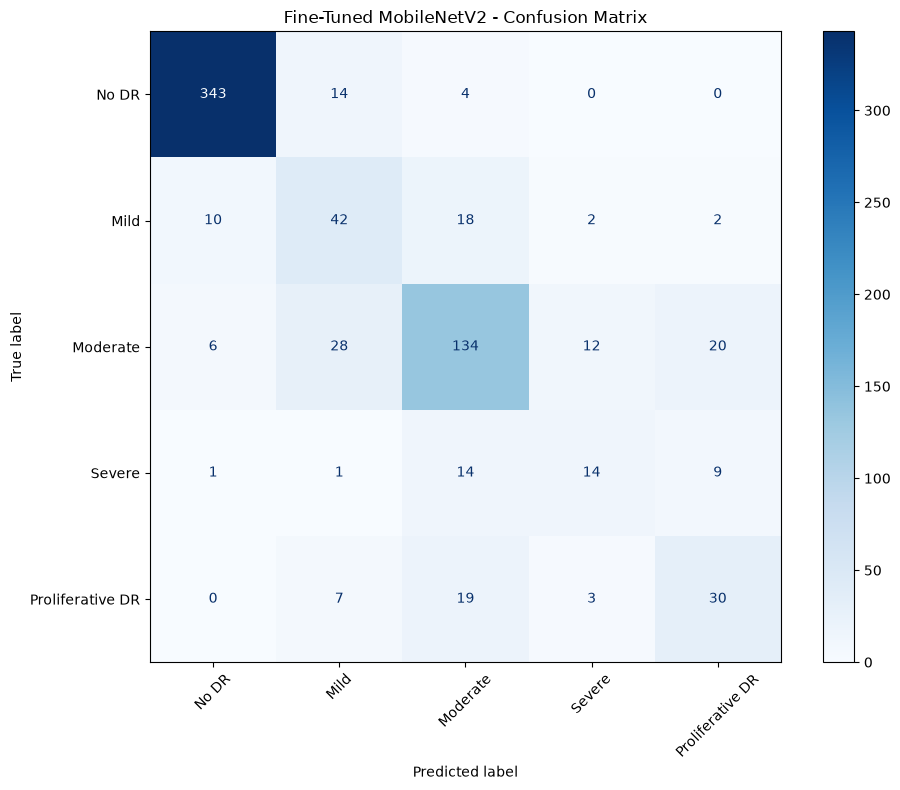

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
FINAL_MODEL_PATH = MODEL_DIR / "final_mobilenetv2_candidate.keras"

final_candidate_model.save(FINAL_MODEL_PATH)

print("Final candidate model saved successfully!")
print("Location:", FINAL_MODEL_PATH)

Final candidate model saved successfully!
Location: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\final_mobilenetv2_candidate.keras
